# 01 · Problem Definition & Exploratory Data Analysis
**Intel Scene Classification with a CNN Trained From Scratch (TensorFlow / Keras)**  
*Section 1* · MSc Data Science project · Dr. Spoorthi H S

**In this notebook**
- 6-class scene classification: buildings, forest, glacier, mountain, sea, street
- Reproducible setup: global seed, deterministic ops, mixed precision, one CFG dictionary
- 17,034 labelled images (14,034 train / 3,000 test), near-balanced (imbalance 1.15x)
- EDA: class distribution, raw samples per class, image dimensions, per-class RGB chromaticity

> **How to use these notebooks.** The outputs below come from one complete training run on a Kaggle Tesla T4 GPU. Each part builds on objects created earlier (configuration, data pipelines, the trained model), so the part notebooks are for reading and review. To reproduce the results, run [`00_full_pipeline_run_all.ipynb`](00_full_pipeline_run_all.ipynb) top to bottom.

[Pre-Processing & Augmentation Pipeline →](02_preprocessing_and_augmentation.ipynb)

---

#  Intel Image Classification — CNN Trained From Scratch (No Transfer Learning)
> **Framework:** TensorFlow 2 / Keras &nbsp;|&nbsp; **Architecture:** DeepSceneNet, a custom residual CNN with SE and spatial attention (13.1 M parameters, built from scratch)  
> **Result:** **89.03 % test accuracy** and **97.37 % top-2 accuracy** on 3,000 held-out images (target was ≥ 90 %) &nbsp;|&nbsp; **Techniques:** MixUp · CutMix · Label Smoothing · Cosine LR with Warmup · Mixed Precision · TTA · Grad-CAM

---
| # | Section |
|---|---------|
| 1️. | Problem Definition & Data Understanding |
| 2️. | Data Pre-Processing & Input Pipeline |
| 3️. | Model Design in Keras |
| 4️. | Model Training (3-Phase Schedule) |
| 5️. | Evaluation & Error Analysis |
| 6️. | Reproducibility & Code Quality |

---
## 1️⃣ Problem Definition & Data Understanding

### 1.1 Task Description
**Problem:** Multi-class image scene classification into 6 categories.

| Class | Typical Visual Cues |
|-------|-------------------|
| `buildings` | Rectangular structures, glass, concrete |
| `forest`    | Dense green foliage, trees |
| `glacier`   | Blue-white ice, snow fields |
| `mountain`  | Rocky peaks, slopes, skyline |
| `sea`       | Horizon, water, waves |
| `street`    | Roads, pavements, urban signs |

**Dataset:** Intel Image Classification - 17,034 labelled colour JPEGs at 150×150 px (14,034 train / 3,000 test; the public release also contains about 7,000 unlabelled prediction images, which are not used)  
**Challenge:** High inter-class similarity (glacier ↔ mountain, sea ↔ glacier, buildings ↔ street)  
**Approach:** Custom deep CNN trained from scratch — no pre-trained weights.

### 1.2 Install & Import Dependencies

In [ ]:
# ─── Kaggle GPU check ──────────────────────────────────────────────────────
import subprocess
result = subprocess.run(['nvidia-smi'], capture_output=True, text=True)
print(result.stdout[:800] if result.returncode == 0 else "No GPU detected")


Wed Mar 18 02:04:29 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.105.08             Driver Version: 580.105.08     CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   35C    P8              9


In [ ]:
# ─── Standard library ─────────────────────────────────────────────────────────
import os, sys, json, random, warnings, zipfile, time, itertools
from pathlib import Path
from collections import Counter
warnings.filterwarnings("ignore")

# ─── Scientific / Viz ─────────────────────────────────────────────────────────
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot   as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
sns.set_theme(style="whitegrid", palette="tab10")

# ─── TensorFlow / Keras ──────────────────────────────────────────────────────
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, Model, regularizers, optimizers, callbacks
import tensorflow.keras.backend as K

# ─── Sklearn ──────────────────────────────────────────────────────────────────
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_curve, auc, average_precision_score)
from sklearn.preprocessing   import label_binarize
from sklearn.model_selection import StratifiedShuffleSplit

print(f"Python     : {sys.version.split()[0]}")
print(f"TensorFlow : {tf.__version__}")
print(f"GPU(s)     : {tf.config.list_physical_devices('GPU')}")


2026-03-18 02:04:38.016382: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1773799478.412521      55 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1773799478.520428      55 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1773799479.494458      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773799479.494505      55 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1773799479.494509      55 computation_placer.cc:177] computation placer alr

Python     : 3.12.12
TensorFlow : 2.19.0
GPU(s)     : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


### 1.3 Global Configuration (Single Source of Truth)

In [ ]:
# ─── Reproducibility — MUST run before anything else ─────────────────────────
SEED = 42
os.environ["PYTHONHASHSEED"]       = str(SEED)
os.environ["TF_DETERMINISTIC_OPS"] = "1"
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.keras.backend.clear_session()

# ─── Kaggle GPU: enable memory growth ─────────────────────────────────────────
gpus = tf.config.list_physical_devices("GPU")
if gpus:
    for gpu in gpus:
        tf.config.experimental.set_memory_growth(gpu, True)
    print(f" GPU memory growth enabled — {len(gpus)} GPU(s) found")

# ─── Mixed precision (float16 compute, float32 variables) ─────────────────────
tf.keras.mixed_precision.set_global_policy("mixed_float16")
print(f" Mixed precision policy : {tf.keras.mixed_precision.global_policy().name}")

# ─── Auto-detect dataset path (handles any Kaggle folder structure) ───────────
import glob as _glob

def _find_class_dir(base, split_keywords):
    """Walk /kaggle/input and find the folder that contains the 6 class folders."""
    CLASSES = {"buildings","forest","glacier","mountain","sea","street"}
    for root, dirs, _ in os.walk(base):
        if CLASSES.issubset({d.lower() for d in dirs}):
            # Check the split keyword is somewhere in root path
            root_lower = root.lower()
            if any(kw in root_lower for kw in split_keywords):
                return Path(root)
    # Fallback: return first dir that has all 6 classes regardless of keyword
    for root, dirs, _ in os.walk(base):
        if CLASSES.issubset({d.lower() for d in dirs}):
            return Path(root)
    return None

_INPUT_BASE = "/kaggle/input"
_TRAIN_DIR  = _find_class_dir(_INPUT_BASE, ["seg_train", "train"])
_TEST_DIR   = _find_class_dir(_INPUT_BASE, ["seg_test",  "test", "pred"])

assert _TRAIN_DIR is not None, (
    "  Could not locate training folder under /kaggle/input\n"
    "    → Go to 'Add data' in your notebook and add: "
    "puneet6060/intel-image-classification")
assert _TEST_DIR  is not None and _TEST_DIR != _TRAIN_DIR, (
    " Could not locate test folder under /kaggle/input")

print(f" TRAIN_DIR auto-detected : {_TRAIN_DIR}")
print(f"  TEST_DIR  auto-detected : {_TEST_DIR}")

# ─── All hyper-parameters in one dict ─────────────────────────────────────────
CFG = dict(
    # Paths — auto-detected above
    TRAIN_DIR     = _TRAIN_DIR,
    TEST_DIR      = _TEST_DIR,
    CKPT_PATH     = "/kaggle/working/best_cnn_model.keras",

    # Image
    IMG_SIZE      = 150,
    NUM_CLASSES   = 6,
    CLASSES       = ["buildings","forest","glacier","mountain","sea","street"],

    # Pipeline — batch 128 fits comfortably on T4 with mixed precision
    BATCH_SIZE    = 128,
    VAL_SPLIT     = 0.15,

    # Phase 1 — train from scratch, higher LR
    EPOCHS_P1     = 40,
    LR_P1         = 1e-3,

    # Phase 2 — reduce LR, harder convergence
    EPOCHS_P2     = 30,
    LR_P2         = 2e-4,

    # Phase 3 — final fine convergence
    EPOCHS_P3     = 20,
    LR_P3         = 5e-5,

    # Learning Rate Schedule
    WARMUP_EPOCHS = 5,

    # Regularisation
    LABEL_SMOOTH  = 0.10,
    DROPOUT       = 0.50,
    L2_REG        = 2e-4,

    # Augmentation
    MIXUP_ALPHA   = 0.30,
    CUTMIX_ALPHA  = 0.30,

    # TTA
    TTA_STEPS     = 10,

    SEED          = SEED,
    AUTOTUNE      = tf.data.AUTOTUNE,
)

CLASS_TO_IDX = {c:i for i,c in enumerate(CFG["CLASSES"])}
IDX_TO_CLASS = {i:c for c,i in CLASS_TO_IDX.items()}
PALETTE      = plt.cm.Set2(np.linspace(0,1,6))

print("\n── CONFIG " + "─"*50)
for k,v in CFG.items():
    if k not in ("AUTOTUNE",):
        print(f"  {k:<16} = {v}")


 GPU memory growth enabled — 2 GPU(s) found
 Mixed precision policy : mixed_float16
 TRAIN_DIR auto-detected : /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
  TEST_DIR  auto-detected : /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test

── CONFIG ──────────────────────────────────────────────────
  TRAIN_DIR        = /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
  TEST_DIR         = /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test
  CKPT_PATH        = /kaggle/working/best_cnn_model.keras
  IMG_SIZE         = 150
  NUM_CLASSES      = 6
  CLASSES          = ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
  BATCH_SIZE       = 128
  VAL_SPLIT        = 0.15
  EPOCHS_P1        = 40
  LR_P1            = 0.001
  EPOCHS_P2        = 30
  LR_P2            = 0.0002
  EPOCHS_P3        = 20
  LR_P3            = 5e-05
  WARMUP_EPOCHS    = 5
  LABEL_SMOOTH    

### 1.4 Dataset Download

In [ ]:
# ─── Verify dataset is accessible and print counts ───────────────────────────
print("Verifying dataset paths …")
for d in [CFG["TRAIN_DIR"], CFG["TEST_DIR"]]:
    classes = sorted(p.name for p in d.iterdir() if p.is_dir())
    n_imgs  = sum(len(list(p.glob("*.jpg"))) for p in d.iterdir() if p.is_dir())
    print(f"    {d}")
    print(f"      Classes : {classes}")
    print(f"      Images  : {n_imgs:,}")
print("\n  Dataset ready.")


Verifying dataset paths …
    /kaggle/input/datasets/puneet6060/intel-image-classification/seg_train/seg_train
      Classes : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
      Images  : 14,034
    /kaggle/input/datasets/puneet6060/intel-image-classification/seg_test/seg_test
      Classes : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
      Images  : 3,000

  Dataset ready.


### 1.5 Exploratory Data Analysis (EDA)

In [ ]:
# ─── Image counts per class ───────────────────────────────────────────────────
def count_images(root):
    return {d.name: len(list(d.glob("*.jpg"))+list(d.glob("*.png")))
            for d in sorted(root.iterdir()) if d.is_dir()}

train_counts = count_images(CFG["TRAIN_DIR"])
test_counts  = count_images(CFG["TEST_DIR"])

df = pd.DataFrame({"Train": train_counts, "Test": test_counts})
df["Train%"] = (df.Train / df.Train.sum()*100).round(1)
df["Test%"]  = (df.Test  / df.Test.sum() *100).round(1)
print(df.to_string())
print(f"\nTotal train : {df.Train.sum():,}")
print(f"Total test  : {df.Test.sum():,}")
print(f"Imbalance   : {df.Train.max()/df.Train.min():.2f}×  (near-balanced )")


           Train  Test  Train%  Test%
buildings   2191   437    15.6   14.6
forest      2271   474    16.2   15.8
glacier     2404   553    17.1   18.4
mountain    2512   525    17.9   17.5
sea         2274   510    16.2   17.0
street      2382   501    17.0   16.7

Total train : 14,034
Total test  : 3,000
Imbalance   : 1.15×  (near-balanced )


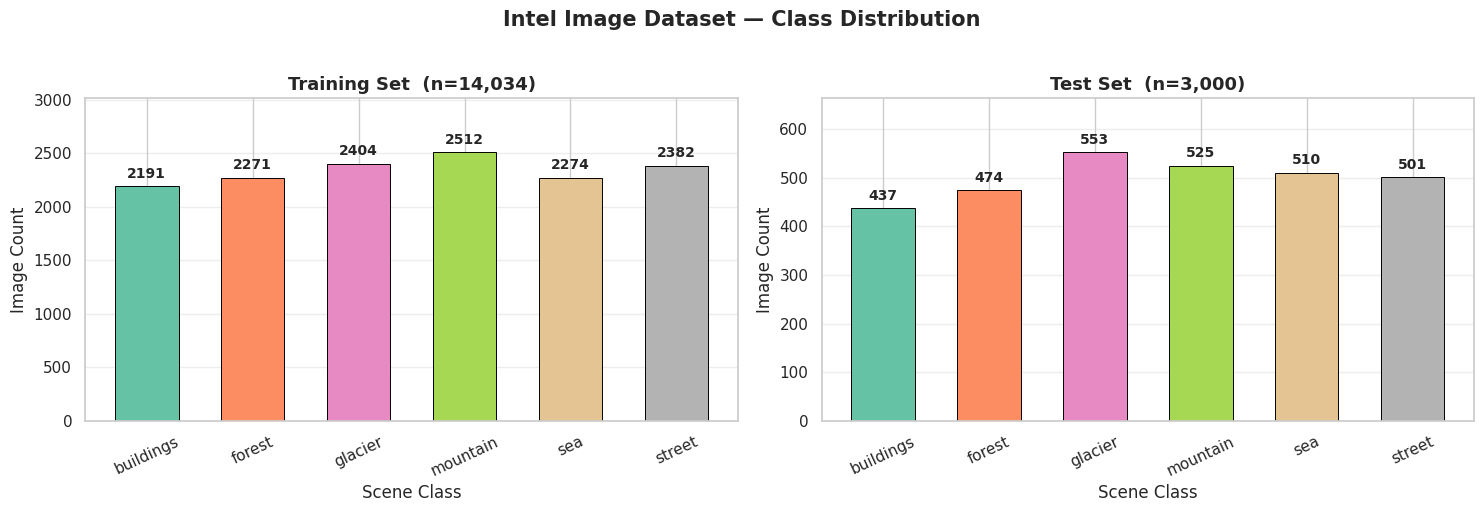

In [ ]:
# ─── Class distribution bar chart ─────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, (counts, title) in zip(axes,
        [(train_counts,"Training Set"),(test_counts,"Test Set")]):
    bars = ax.bar(counts.keys(), counts.values(),
                  color=PALETTE, edgecolor="k", linewidth=0.7, width=0.6)
    ax.bar_label(bars, padding=4, fontsize=10, fontweight="bold")
    ax.set_title(f"{title}  (n={sum(counts.values()):,})",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Scene Class"); ax.set_ylabel("Image Count")
    ax.tick_params(axis="x", rotation=25)
    ax.set_ylim(0, max(counts.values())*1.20)
    ax.grid(axis="y", alpha=0.35)
plt.suptitle("Intel Image Dataset — Class Distribution",
             fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig("eda_class_dist.png", dpi=150, bbox_inches="tight"); plt.show()


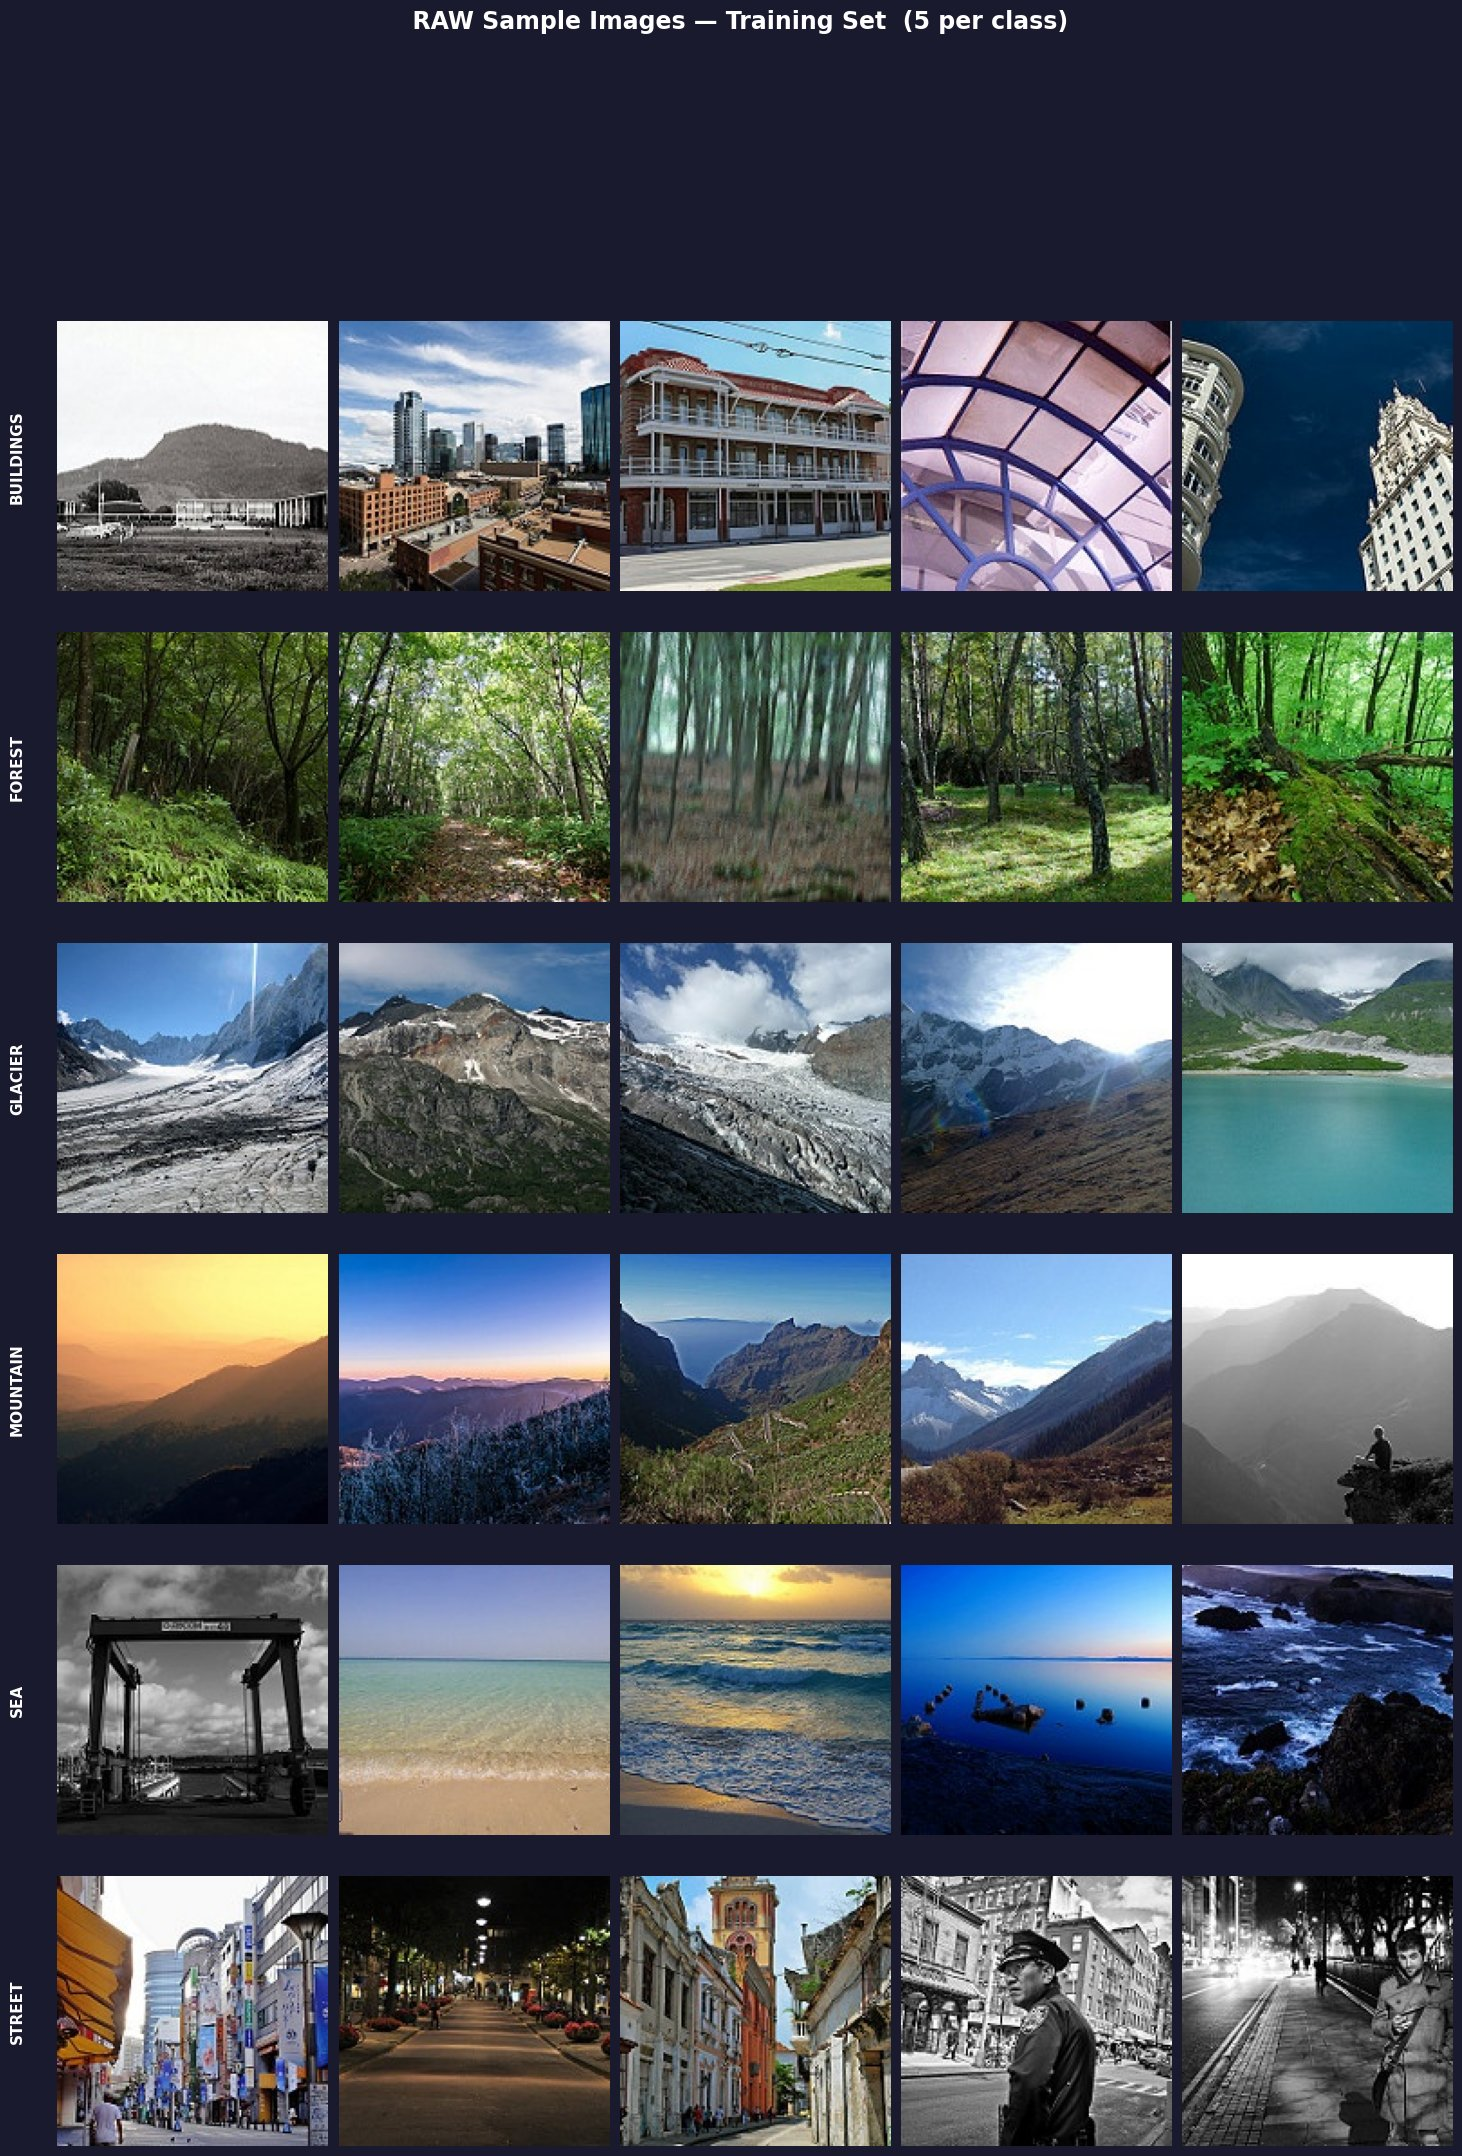

  Raw sample grid saved → raw_samples.png


In [ ]:
# ─── RAW sample images — 5 per class ─────────────────────────────────────────
fig = plt.figure(figsize=(18, 24))
fig.patch.set_facecolor("#1a1a2e")
fig.suptitle("  RAW Sample Images — Training Set  (5 per class)",
             fontsize=17, fontweight="bold", color="white", y=1.005)
gs = gridspec.GridSpec(6, 5, figure=fig, hspace=0.06, wspace=0.04)

CLASS_COLORS = ["#e74c3c","#27ae60","#2980b9","#8e44ad","#f39c12","#16a085"]
for row, cls in enumerate(CFG["CLASSES"]):
    paths = sorted((CFG["TRAIN_DIR"]/cls).glob("*.jpg"))[:5]
    for col, p in enumerate(paths):
        ax = fig.add_subplot(gs[row, col])
        img = np.array(Image.open(p).convert("RGB"))
        ax.imshow(img); ax.axis("off")
        for spine in ax.spines.values():
            spine.set_edgecolor(CLASS_COLORS[row]); spine.set_linewidth(3)
        if col == 0:
            ax.text(-0.12, 0.5, cls.upper(), transform=ax.transAxes,
                    fontsize=11, fontweight="bold", color="white", va="center",
                    ha="right", rotation=90)
plt.savefig("raw_samples.png", dpi=120, bbox_inches="tight"); plt.show()
print("  Raw sample grid saved → raw_samples.png")


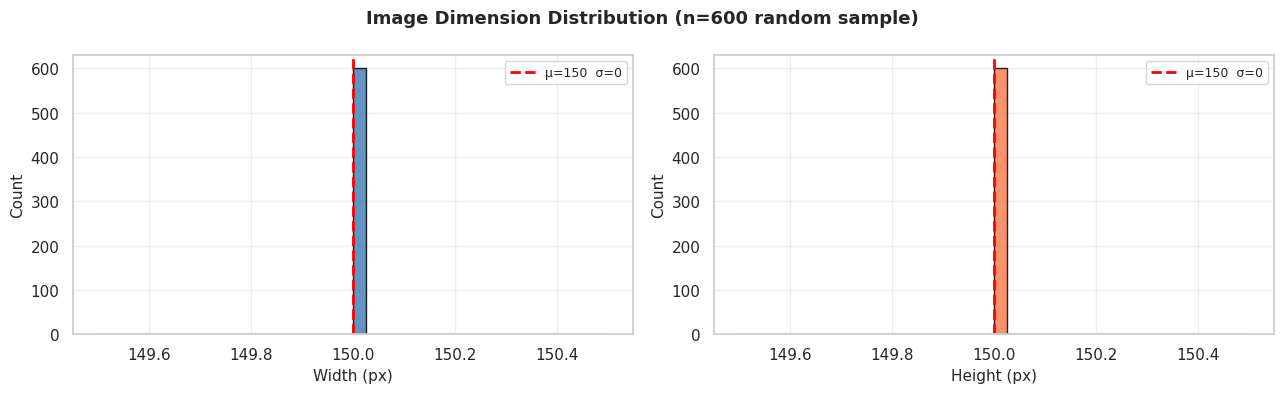

Width  μ=150 min=150 max=150
Height μ=150 min=150 max=150


In [ ]:
# ─── Image dimension distribution ────────────────────────────────────────────
all_paths = list(CFG["TRAIN_DIR"].rglob("*.jpg"))
sample    = random.sample(all_paths, min(600, len(all_paths)))
widths, heights = [], []
for p in sample:
    with Image.open(p) as im:
        w,h = im.size; widths.append(w); heights.append(h)

fig, axes = plt.subplots(1,2, figsize=(13,4))
for ax,(data,lbl,c) in zip(axes,[
    (widths,"Width (px)","steelblue"),(heights,"Height (px)","coral")]):
    ax.hist(data, bins=40, color=c, edgecolor="k", alpha=0.85)
    ax.axvline(np.mean(data), color="red", ls="--", lw=2,
               label=f"μ={np.mean(data):.0f}  σ={np.std(data):.0f}")
    ax.set_xlabel(lbl,fontsize=11); ax.set_ylabel("Count",fontsize=11)
    ax.legend(fontsize=9); ax.grid(alpha=0.35)
plt.suptitle("Image Dimension Distribution (n=600 random sample)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("eda_dims.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Width  μ={np.mean(widths):.0f} min={min(widths)} max={max(widths)}")
print(f"Height μ={np.mean(heights):.0f} min={min(heights)} max={max(heights)}")


Computing per-class RGB means … done


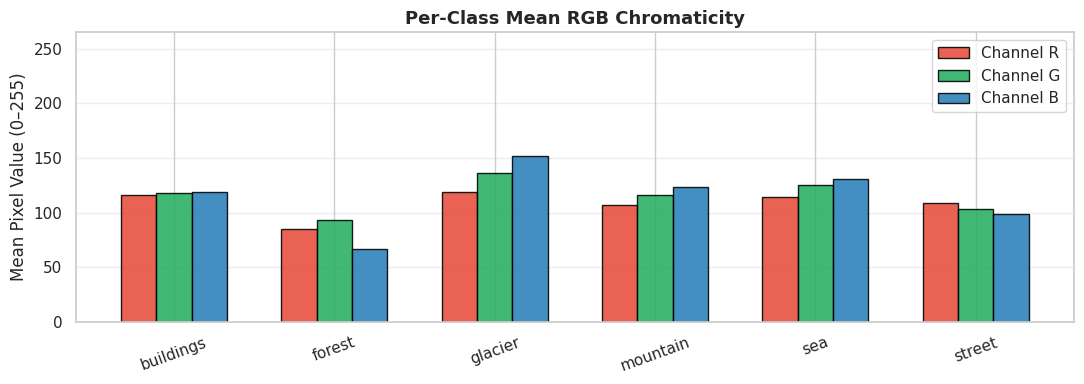

In [ ]:
# ─── Per-class mean RGB chromaticity ─────────────────────────────────────────
print("Computing per-class RGB means … ", end="", flush=True)
class_rgb = {}
for cls in CFG["CLASSES"]:
    imgs = sorted((CFG["TRAIN_DIR"]/cls).glob("*.jpg"))[:100]
    arr  = np.stack([np.array(Image.open(p).convert("RGB")
                    .resize((64,64)), dtype=np.float32) for p in imgs])
    class_rgb[cls] = arr.mean(axis=(0,1,2))
print("done")

fig, ax = plt.subplots(figsize=(11,4))
x = np.arange(len(CFG["CLASSES"])); w = 0.22
for i,(ch,col) in enumerate(zip(["R","G","B"],["#e74c3c","#27ae60","#2980b9"])):
    vals = [class_rgb[c][i] for c in CFG["CLASSES"]]
    ax.bar(x+(i-1)*w, vals, w, label=f"Channel {ch}", color=col, alpha=0.88, edgecolor="k")
ax.set_xticks(x); ax.set_xticklabels(CFG["CLASSES"], rotation=20)
ax.set_ylabel("Mean Pixel Value (0–255)"); ax.set_ylim(0,265)
ax.set_title("Per-Class Mean RGB Chromaticity", fontsize=13, fontweight="bold")
ax.legend(); ax.grid(axis="y", alpha=0.35)
plt.tight_layout()
plt.savefig("eda_rgb.png", dpi=150, bbox_inches="tight"); plt.show()


---

[Next: Pre-Processing & Augmentation Pipeline →](02_preprocessing_and_augmentation.ipynb)